<a href="https://colab.research.google.com/github/jluzande/computer-vision-projects/blob/main/lab_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

OpenCV version: 5.0.0
Image 1: (512, 512) | Image 2: (512, 512)


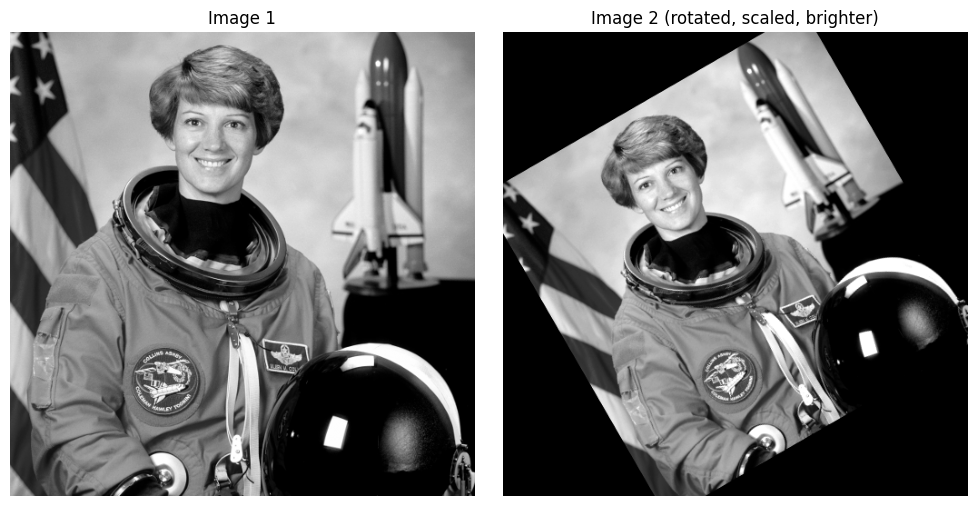

SURF is NOT available in this OpenCV build (non-free module disabled).
Falling back to SIFT and ORB below. Mention this in your report; the SURF code
paths in this cell will run as-is on an OpenCV build compiled with OPENCV_ENABLE_NONFREE=ON.

Method  Keypoints  Desc. len  Time (ms)  Good matches
SIFT         1105        128      261.1           600
ORB          1000         32       20.4           489


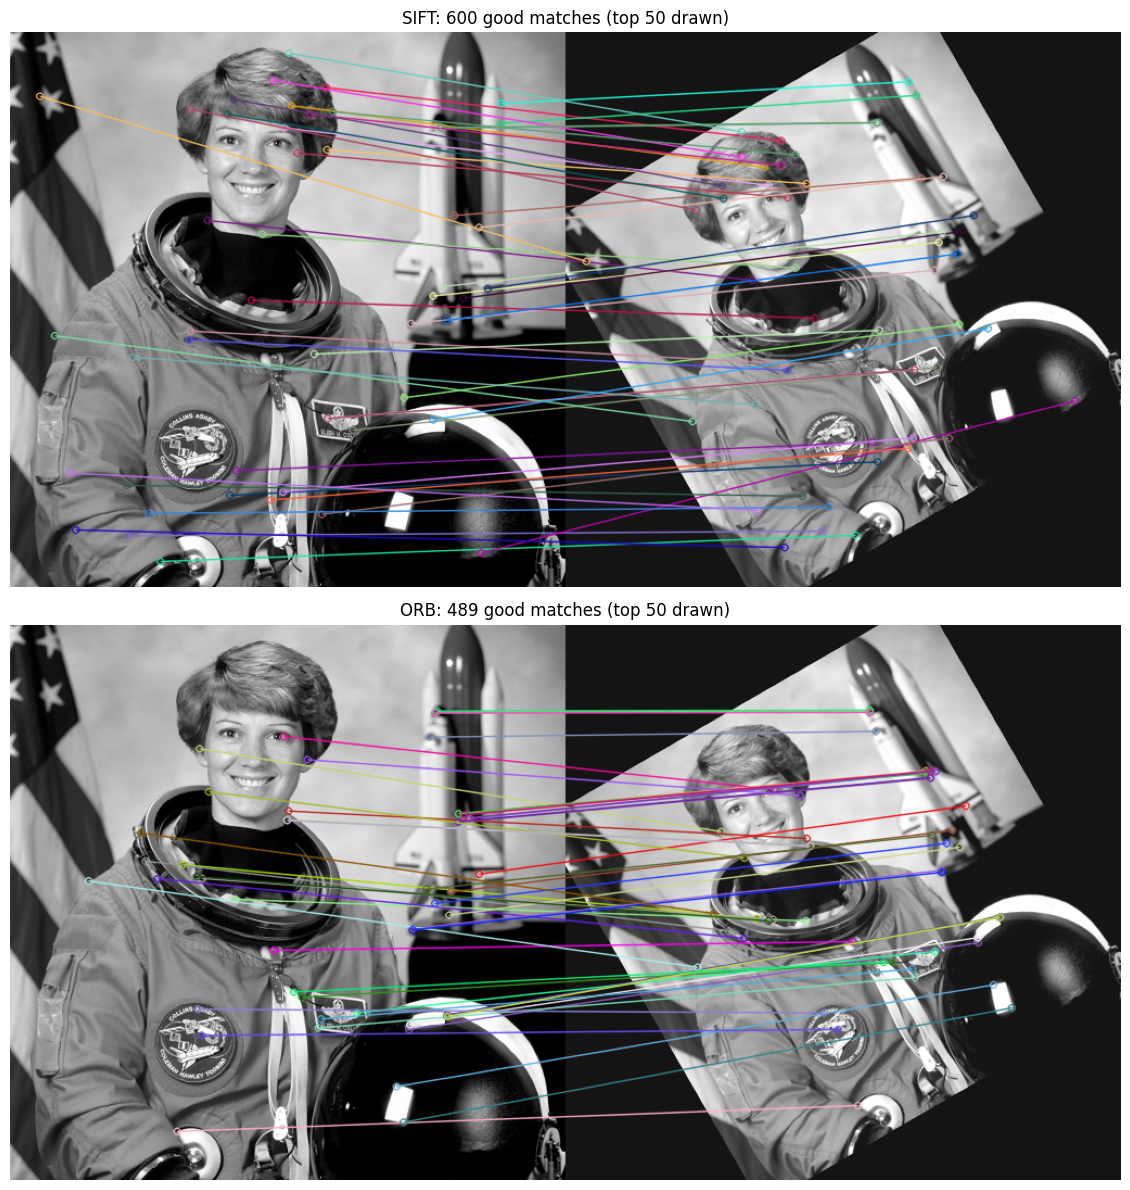

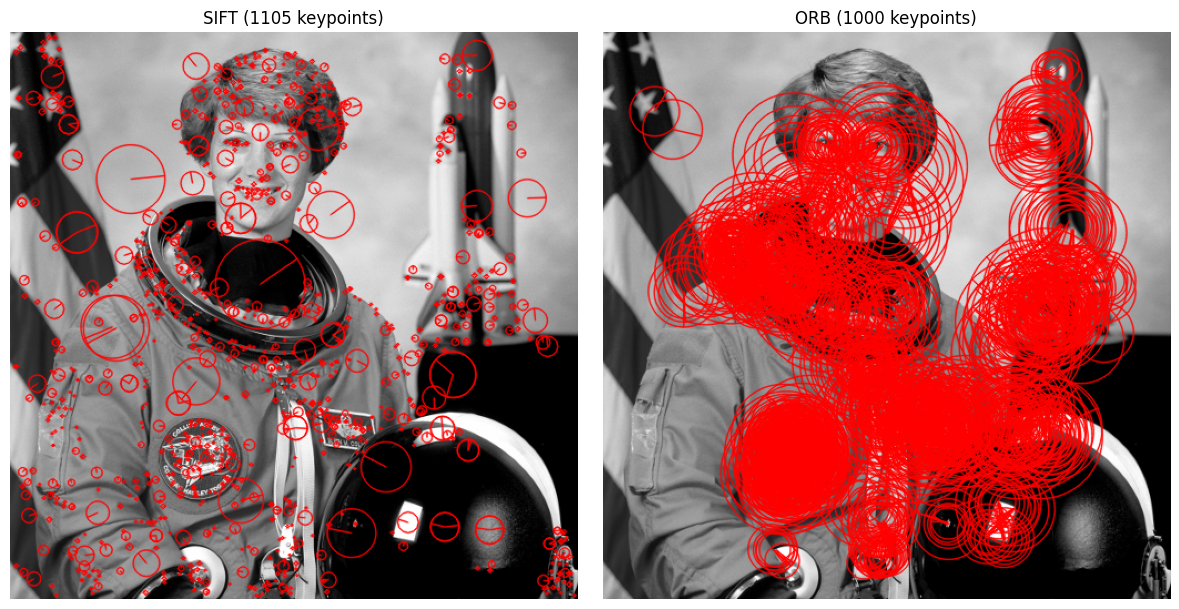


--- Effect of threshold on number of keypoints ---
SIFT contrastThreshold 0.01 : 1797 keypoints
SIFT contrastThreshold 0.02 : 1509 keypoints
SIFT contrastThreshold 0.04 : 1105 keypoints
SIFT contrastThreshold 0.08 : 654 keypoints
SIFT contrastThreshold 0.12 : 383 keypoints


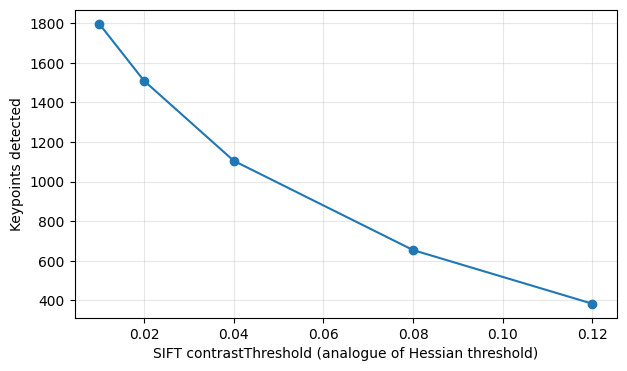


--- U-SURF ---
Skipped: SURF unavailable in this OpenCV build.
Equivalent idea: U-SURF skips orientation assignment, so it is faster but breaks on rotated images.


In [1]:
import cv2
import time
import numpy as np
import matplotlib.pyplot as plt

print("OpenCV version:", cv2.__version__)

# ============================================================
# 1. Load image (grayscale)
# ============================================================
UPLOAD_IMAGE = False   # set True to upload your own image(s) instead of the built-in sample

if UPLOAD_IMAGE:
    from google.colab import files
    uploaded = files.upload()
    names = list(uploaded.keys())
    img = cv2.imread(names[0], cv2.IMREAD_GRAYSCALE)
    # second image for matching (optional): upload two files, else a transformed copy is made below
    img2 = cv2.imread(names[1], cv2.IMREAD_GRAYSCALE) if len(names) > 1 else None
else:
    from skimage import data
    img = cv2.cvtColor(data.astronaut(), cv2.COLOR_RGB2GRAY)   # built-in sample image
    img2 = None

if img is None:
    raise SystemExit("Error loading image")

# If no 2nd image was given, create one: rotate 30 deg + scale 0.8 + brightness change
if img2 is None:
    hh, ww = img.shape
    M = cv2.getRotationMatrix2D((ww / 2, hh / 2), 30, 0.8)
    img2 = cv2.warpAffine(img, M, (ww, hh))
    img2 = cv2.convertScaleAbs(img2, alpha=1.0, beta=20)

print("Image 1:", img.shape, "| Image 2:", img2.shape)

def show(images, titles, cols=3, size=(15, 5)):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=(size[0], size[1] * rows))
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        plt.imshow(im, cmap='gray' if im.ndim == 2 else None)
        plt.title(t)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

show([img, img2], ["Image 1", "Image 2 (rotated, scaled, brighter)"], cols=2, size=(10, 5))

# ============================================================
# 2. Create SURF detector, detect keypoints and descriptors
# ============================================================
# NOTE: SURF is patented/non-free. Standard pip builds of OpenCV (including the
# one in Colab) usually do NOT include it, so we check first.
def make_surf(hessian, upright=False):
    try:
        return cv2.xfeatures2d.SURF_create(hessianThreshold=hessian, upright=upright)
    except (AttributeError, cv2.error):
        return None

hessian_threshold = 400
surf = make_surf(hessian_threshold)
SURF_OK = surf is not None

if SURF_OK:
    print("SURF is available.")
    keypoints, descriptors = surf.detectAndCompute(img, None)
    print(f"Number of keypoints detected: {len(keypoints)}")
    print("Descriptor shape:", descriptors.shape)   # (N, 64)

    # ========================================================
    # 3. Draw keypoints (rich keypoints show size + orientation)
    # ========================================================
    img_kp = cv2.drawKeypoints(img, keypoints, None, (0, 0, 255),
                               cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    show([cv2.cvtColor(img_kp, cv2.COLOR_BGR2RGB)], ["SURF Keypoints"], cols=1, size=(7, 7))
else:
    print("SURF is NOT available in this OpenCV build (non-free module disabled).")
    print("Falling back to SIFT and ORB below. Mention this in your report; the SURF code")
    print("paths in this cell will run as-is on an OpenCV build compiled with OPENCV_ENABLE_NONFREE=ON.")

# ============================================================
# LAB ACTIVITY 1 & 2: Feature matching + compare SURF vs SIFT vs ORB
# ============================================================
detectors = {}
if SURF_OK:
    detectors["SURF"] = (make_surf(hessian_threshold), cv2.NORM_L2)
detectors["SIFT"] = (cv2.SIFT_create(), cv2.NORM_L2)
detectors["ORB"] = (cv2.ORB_create(nfeatures=1000), cv2.NORM_HAMMING)

def match_features(d1, d2, norm, ratio=0.75):
    """Brute-force kNN matching + Lowe's ratio test."""
    bf = cv2.BFMatcher(norm)
    knn = bf.knnMatch(d1, d2, k=2)
    return [m[0] for m in knn if len(m) == 2 and m[0].distance < ratio * m[1].distance]

results = []
match_imgs, match_titles = [], []

for name, (det, norm) in detectors.items():
    t0 = time.time()
    kp1, d1 = det.detectAndCompute(img, None)
    t_detect = time.time() - t0
    kp2, d2 = det.detectAndCompute(img2, None)

    good = match_features(d1, d2, norm)
    good = sorted(good, key=lambda m: m.distance)

    vis = cv2.drawMatches(img, kp1, img2, kp2, good[:50], None,
                          flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    match_imgs.append(vis)
    match_titles.append(f"{name}: {len(good)} good matches (top 50 drawn)")
    results.append((name, len(kp1), d1.shape[1], t_detect * 1000, len(good)))

print(f"\n{'Method':<6} {'Keypoints':>10} {'Desc. len':>10} {'Time (ms)':>10} {'Good matches':>13}")
for r in results:
    print(f"{r[0]:<6} {r[1]:>10} {r[2]:>10} {r[3]:>10.1f} {r[4]:>13}")

show(match_imgs, match_titles, cols=1, size=(14, 6))

# Keypoints side by side
kp_imgs, kp_titles = [], []
for name, (det, norm) in detectors.items():
    kp, _ = det.detectAndCompute(img, None)
    kp_imgs.append(cv2.drawKeypoints(img, kp, None, (0, 0, 255),
                                     cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS))
    kp_titles.append(f"{name} ({len(kp)} keypoints)")
show([cv2.cvtColor(k, cv2.COLOR_BGR2RGB) for k in kp_imgs], kp_titles, cols=len(kp_imgs), size=(6 * len(kp_imgs), 6))

# ============================================================
# Effect of the Hessian threshold (Question 1)
# ============================================================
print("\n--- Effect of threshold on number of keypoints ---")
if SURF_OK:
    thresholds = [100, 200, 400, 800, 1500, 3000]
    counts = []
    for th in thresholds:
        kp = make_surf(th).detect(img, None)
        counts.append(len(kp))
        print(f"Hessian threshold {th:>5}: {len(kp)} keypoints")
    plt.figure(figsize=(7, 4))
    plt.plot(thresholds, counts, marker='o')
    plt.xlabel("Hessian threshold")
    plt.ylabel("Keypoints detected")
    plt.title("SURF: Hessian threshold vs. keypoints")
    plt.grid(alpha=0.3)
    plt.show()
else:
    # Analogous experiment with SIFT's contrastThreshold (higher -> fewer keypoints)
    ths = [0.01, 0.02, 0.04, 0.08, 0.12]
    counts = []
    for th in ths:
        kp = cv2.SIFT_create(contrastThreshold=th).detect(img, None)
        counts.append(len(kp))
        print(f"SIFT contrastThreshold {th:<5}: {len(kp)} keypoints")
    plt.figure(figsize=(7, 4))
    plt.plot(ths, counts, marker='o')
    plt.xlabel("SIFT contrastThreshold (analogue of Hessian threshold)")
    plt.ylabel("Keypoints detected")
    plt.grid(alpha=0.3)
    plt.show()

# ============================================================
# LAB ACTIVITY 3: U-SURF (upright SURF, no orientation assignment)
# ============================================================
print("\n--- U-SURF ---")
if SURF_OK:
    surf_std = make_surf(hessian_threshold, upright=False)
    surf_up = make_surf(hessian_threshold, upright=True)

    for label, s in [("SURF (rotation invariant)", surf_std), ("U-SURF (upright)", surf_up)]:
        t0 = time.time()
        kp1, d1 = s.detectAndCompute(img, None)
        t = (time.time() - t0) * 1000
        kp2, d2 = s.detectAndCompute(img2, None)   # img2 is rotated 30 deg
        good = match_features(d1, d2, cv2.NORM_L2)
        print(f"{label:<28} keypoints={len(kp1):>5}  time={t:6.1f} ms  good matches on rotated image={len(good)}")

    kp_u, _ = surf_up.detectAndCompute(img, None)
    vis = cv2.drawKeypoints(img, kp_u, None, (0, 0, 255), cv2.DRAW_MATCHES_FLAGS_DRAW_RICH_KEYPOINTS)
    show([cv2.cvtColor(vis, cv2.COLOR_BGR2RGB)], ["U-SURF keypoints (all point upright)"], cols=1, size=(7, 7))
else:
    print("Skipped: SURF unavailable in this OpenCV build.")
    print("Equivalent idea: U-SURF skips orientation assignment, so it is faster but breaks on rotated images.")